[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Naviden/Introduction-to-XAI/blob/main/Tools/TextComparison_examples/Shared_Text_Comparison.ipynb)

[Colab setup: dependencies and repository files](https://github.com/Naviden/Introduction-to-XAI/blob/main/docs/REPRODUCIBILITY.md#google-colab)

# Shared text comparison: one model, one review, one target

**Question:** how do local contributions, surrogate explanations, deletion effects and sufficient rules describe the same text prediction?

Fit a **TF-IDF + logistic regression** classifier on the bundled sentence-polarity reviews. Compare SHAP, LIME, word-type occlusion and Anchors using one explicit word-deletion representation. Inspect an exact decomposition of the fitted model as a separate reference; it is not assumed to equal raw-word deletion effects.

**Setup:** the tabular requirements plus `anchor-exp==0.0.2.0` (also included in the full requirements). No language models, spaCy models, GPU, Java or network downloads are used. Run from this folder with `text_helpers.py` beside the notebook. The existing corpus is read from `../ANCHOR_examples/rt-polaritydata/`.

**Protocol:** split duplicate normalized sentences together, select a 12-case cohort before inspecting predictions, and use its first row as the shared case. Report errors as well as correct predictions. This is an educational experiment on historical snippets, not a claim of state-of-the-art sentiment recognition or a universal explainer ranking.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from anchor import anchor_tabular
from lime.lime_tabular import LimeTabularExplainer
from scipy.special import expit
from scipy.stats import binomtest
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from text_helpers import (WordMasker, coordinate_contributions, deletion_curve,
                          load_reviews, similarity, target_margin, tokenize)

SEED = 42
CLASS_NAMES = ['negative', 'positive']
ROOT = Path.cwd().resolve().parents[1]
assert (ROOT / 'README.md').exists(), 'Run from Tools/TextComparison_examples/.'
OUTPUT = ROOT / 'validation' / 'text-comparison'
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print({name: importlib.metadata.version(name) for name in ['numpy', 'scikit-learn', 'shap', 'lime', 'anchor-exp']})

{'numpy': '2.4.6', 'scikit-learn': '1.9.1', 'shap': '0.51.0', 'lime': '0.2.0.1', 'anchor-exp': '0.0.2.0'}


/Users/navid/Documents/Codex/2026-10-28/makew/work/Introduction-to-XAI/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Train one pipeline without learning from the test set

The corpus contains 5,331 negative and 5,331 positive snippets. The loader uses `xai_assets` to verify both bundled files against the SHA-256 hashes in `assets/manifest.json` before parsing. Decode Latin-1 rather than silently dropping accented text, and split records only on LF newlines: the bundled files contain legacy punctuation bytes that Python’s `splitlines()` would mistake for extra rows. The tokenizer case-folds text and keeps Unicode word tokens, including one-letter words and numbers; punctuation and word order are discarded by the unigram model. It uses no stop-word list.

A stratified **group** split keeps identical normalized token sequences together. It cannot separate unknown authors, movies or paraphrases, for which this bundled corpus supplies no identifiers. Vocabulary, document frequencies and logistic coefficients are fitted only on training data. We fix regularization and minimum document frequency before looking at test results.

In [2]:
corpus_directory = ROOT / 'Tools/ANCHOR_examples/rt-polaritydata'
texts, labels = load_reviews(corpus_directory)
assert len(texts) == 10662 and np.bincount(labels).tolist() == [5331, 5331]
normalized = np.array([' '.join(tokenize(text)) for text in texts], dtype=object)
assert all(normalized), 'Empty token sequences need an explicit protocol.'
splitter = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
train_ids, test_ids = next(splitter.split(texts, labels, groups=normalized))
assert set(normalized[train_ids]).isdisjoint(normalized[test_ids])
# Freeze the cohort before fitting or computing any test predictions.
cohort_positions = np.random.default_rng(137).choice(len(test_ids), size=12, replace=False)
cohort_ids = test_ids[cohort_positions]
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(tokenizer=tokenize, token_pattern=None, lowercase=False,
                            ngram_range=(1, 1), min_df=2, norm='l2')),
    ('classifier', LogisticRegression(C=1., max_iter=1500, random_state=SEED)),
])
pipeline.fit(texts[train_ids].tolist(), labels[train_ids])
assert np.array_equal(pipeline.classes_, [0, 1])
test_probability = pipeline.predict_proba(texts[test_ids].tolist())[:, 1]
test_prediction = pipeline.predict(texts[test_ids].tolist())
quality = pd.Series({'training_rows':len(train_ids), 'test_rows':len(test_ids),
                     'learned_vocabulary_size':len(pipeline.named_steps['tfidf'].vocabulary_),
                     'test_accuracy':accuracy_score(labels[test_ids], test_prediction),
                     'test_ROC_AUC':roc_auc_score(labels[test_ids], test_probability),
                     'test_log_loss':log_loss(labels[test_ids], test_probability)})
display(quality)
cohort = pd.DataFrame({'dataset_row':cohort_ids, 'true_label':labels[cohort_ids],
                       'predicted_label':test_prediction[cohort_positions]})
cohort['correct'] = cohort.true_label == cohort.predicted_label
print(f'Prespecified cohort: {int(cohort.correct.sum())} correct and {int((~cohort.correct).sum())} incorrect predictions')
display(cohort)

training_rows              7996.000000
test_rows                  2666.000000
learned_vocabulary_size    8436.000000
test_accuracy                 0.762191
test_ROC_AUC                  0.846847
test_log_loss                 0.519425
dtype: float64

Prespecified cohort: 9 correct and 3 incorrect predictions


,dataset_row,true_label,predicted_label,correct
0,3684,0,0,True
1,6677,1,0,False
2,8823,1,1,True
3,6297,1,1,True
4,4949,0,0,True
5,4500,0,0,True
6,5218,0,0,True
7,9039,1,1,True
8,2934,0,1,False
9,5036,0,0,True


## Fix the case, target and token semantics

Use the first presampled cohort row without filtering by correctness, confidence or explanation appearance. Its **predicted class** becomes the fixed target for every explanation and subsequent control. Logistic regression's target score is the log odds of that class against the other class. Its sigmoid is the target-class probability; log-odds contributions are not probability contributions.

One binary feature represents a **distinct normalized word type**. A zero removes *all* occurrences of that type; a one retains their original counts. Rejoin retained tokens with spaces. The original and rejoined text must have identical predictions for this particular unigram pipeline. This representation would not be prediction-equivalent for a contextual model that uses punctuation and position.

SHAP, LIME, occlusion and Anchor callbacks all use this same reconstruction. Their sampling, weighting and explanatory questions still differ. Words excluded by the training vocabulary remain visible but have no direct encoded feature.

In [3]:
query_id = int(cohort_ids[0])
query_text = str(texts[query_id])
TARGET = int(pipeline.predict([query_text])[0])
masker = WordMasker(query_text)
words = masker.words
d = len(words)
all_present = np.ones((1, d), dtype=int)
all_absent = np.zeros((1, d), dtype=int)

def mask_score(presence):
    return target_margin(pipeline, masker.texts(presence), TARGET)

def mask_class(presence):
    return pipeline.predict(masker.texts(presence))

query_score = float(target_margin(pipeline, [query_text], TARGET)[0])
empty_score = float(mask_score(all_absent)[0])
np.testing.assert_allclose(mask_score(all_present)[0], query_score, atol=1e-12)
np.testing.assert_allclose(expit(query_score), pipeline.predict_proba([query_text])[0, TARGET], atol=1e-12)
print(query_text)
print(f'Dataset row {query_id}: observed {CLASS_NAMES[labels[query_id]]}; predicted/target {CLASS_NAMES[TARGET]}')
print(f'Target log odds: {query_score:.4f}; target probability: {expit(query_score):.4f}')
print(f'{len(masker.tokens)} token occurrences, {d} word-type groups; empty-text target log odds: {empty_score:.4f}')
display(pd.DataFrame({'word_type':words,
                      'occurrences':[masker.tokens.count(word) for word in words],
                      'in_training_vocabulary':[word in pipeline.named_steps['tfidf'].vocabulary_ for word in words]}))

all the sensuality , all the eroticism of a good vampire tale has been , pardon the pun , sucked out and replaced by goth goofiness .
Dataset row 3684: observed negative; predicted/target negative
Target log odds: 0.2774; target probability: 0.5689
23 token occurrences, 20 word-type groups; empty-text target log odds: 0.1761


,word_type,occurrences,in_training_vocabulary
0,all,2,True
1,the,3,True
2,sensuality,1,True
3,eroticism,1,False
4,of,1,True
5,a,1,True
6,good,1,True
7,vampire,1,True
8,tale,1,True
9,has,1,True


## Exact fitted-coordinate contributions are a different reference

The classifier is linear in its **normalized TF-IDF coordinates**: $s(x)=b+\sum_j w_j\,t_j(x)$ for the positive class (negate both coefficients and intercept for the negative class). These products exactly reconstruct the selected target's log odds.

Deleting a word changes the L2 normalization of the remaining TF-IDF vector. Thus, linearity in transformed coordinates does **not** imply an additive raw-word deletion game. We check the reconstruction but do not call these coordinate products ground-truth SHAP values. The empty text maps to the all-zero TF-IDF vector and gives the intercept.

In [4]:
reference_words, exact_terms, exact_baseline = coordinate_contributions(pipeline, query_text, TARGET)
assert reference_words == words
np.testing.assert_allclose(exact_baseline, empty_score, atol=1e-12)
np.testing.assert_allclose(exact_baseline + exact_terms.sum(), query_score, atol=1e-12)
occlusion = query_score - mask_score(1 - np.eye(d, dtype=int))
print(f'Exact TF-IDF reconstruction error: {abs(exact_baseline+exact_terms.sum()-query_score):.3g}')
print('Largest difference between a coordinate term and actual word-type deletion:', float(np.max(np.abs(exact_terms-occlusion))))

Exact TF-IDF reconstruction error: 0
Largest difference between a coordinate term and actual word-type deletion: 0.013088101117851289


## SHAP, LIME and deletion effects on the identical score

**Kernel SHAP** uses the all-absent word mask as its reference, an identity link and 512 sampled coalitions. It allocates the full-minus-empty target log-odds difference under this deletion game. All word groups are included; `l1_reg=0` avoids an extra feature-selection step. Its additivity check is separate from sampling stability.

**LIME** uses the tabular regression interface on the same binary word-presence variables to approximate that same log-odds score. This explicitly controlled masking setup is not the default `LimeTextExplainer` tokenizer. Its artificial training masks are independent Bernoulli draws; categorical-presence encoding and a distance kernel define a weighted neighborhood. Report in-neighborhood fit, the case gap and a fresh held-out mask error.

**Occlusion** asks how much the score drops when each word type is deleted alone. It is not additive because TF-IDF normalization changes. Positive/negative signs always refer to the fixed target score.

In [5]:
def explain_masks(score_function, word_names, seed, shap_budget=512, lime_samples=2000):
    count = len(word_names)
    present = np.ones((1, count), dtype=int)
    absent = np.zeros((1, count), dtype=int)
    np.random.seed(seed)
    started = perf_counter()
    shap_explainer = shap.KernelExplainer(score_function, absent, link='identity')
    shap_values = np.asarray(shap_explainer.shap_values(present, nsamples=shap_budget, l1_reg=0, silent=True))[0]
    shap_seconds = perf_counter() - started
    np.testing.assert_allclose(float(shap_explainer.expected_value) + shap_values.sum(), score_function(present)[0], atol=1e-8)
    mask_training = np.random.default_rng(seed).integers(0, 2, size=(2048, count))
    lime_explainer = LimeTabularExplainer(
        mask_training, mode='regression', feature_names=word_names,
        categorical_features=list(range(count)),
        categorical_names={j:['absent', 'present'] for j in range(count)},
        discretize_continuous=False, feature_selection='none', random_state=seed,
    )
    started = perf_counter()
    lime_explanation = lime_explainer.explain_instance(present[0], score_function,
                                                     num_features=count, num_samples=lime_samples)
    lime_seconds = perf_counter() - started
    weights = np.zeros(count)
    for index, value in lime_explanation.local_exp[1]:
        weights[index] = value
    intercept = float(lime_explanation.intercept[1])
    np.testing.assert_allclose(intercept + weights.sum(), lime_explanation.local_pred[0], atol=1e-10)
    # Fresh masks never used for fitting LIME. Unweighted MAE evaluates a
    # specified uniform deletion distribution, not the weighted fitting loss.
    probe = np.random.default_rng(seed + 10000).integers(0, 2, size=(512, count))
    probe_error = float(np.abs(intercept + probe @ weights - score_function(probe)).mean())
    return {'SHAP':shap_values, 'LIME':weights, 'shap_reference':float(shap_explainer.expected_value),
            'lime_intercept':intercept, 'lime_R2':float(lime_explanation.score),
            'lime_case_gap':float(abs(intercept+weights.sum()-score_function(present)[0])),
            'lime_fresh_mask_MAE':probe_error, 'SHAP_seconds':shap_seconds, 'LIME_seconds':lime_seconds}

shared = explain_masks(mask_score, words, SEED)
diagnostics = pd.Series({key:value for key,value in shared.items() if key not in ['SHAP','LIME']})
display(diagnostics)
print('MAE and case gaps are in target log-odds units. R² is fit under LIME’s sampled weights.')

shap_reference         0.176060
lime_intercept         0.155428
lime_R2                0.961572
lime_case_gap          0.022126
lime_fresh_mask_MAE    0.047247
SHAP_seconds           0.015175
LIME_seconds           0.010941
dtype: float64

MAE and case gaps are in target log-odds units. R² is fit under LIME’s sampled weights.


## Compare signed patterns, not interchangeable magnitudes

All four panels have log-odds-related units, but different definitions: fixed-coordinate products, a Shapley allocation, local surrogate coefficients, and single deletion changes. LIME's intercept differs from the empty-text reference. Agreement alone does not validate an explanation.

For readability, show the same 12 words selected by **absolute exact-coordinate contribution**, with that selection disclosed. The complete table retains every word, including negative and zero effects. This visualization choice does not alter any cohort or diagnostic calculation.

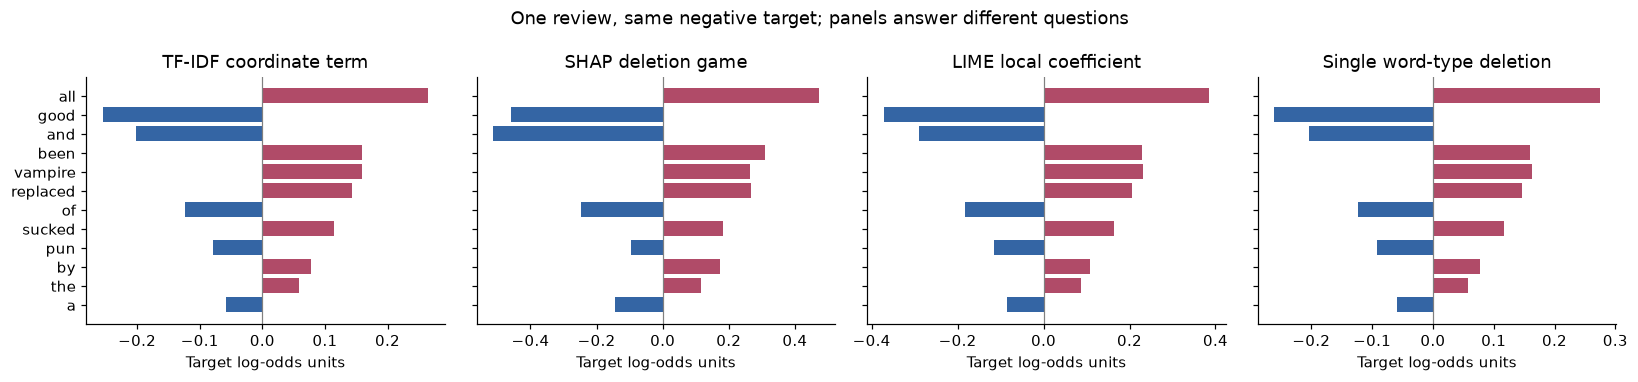

,TF-IDF coordinate term,SHAP deletion game,LIME local coefficient,Single word-type deletion
word_type,,,,
all,0.265292,0.472555,0.385759,0.274503
the,0.058274,0.117163,0.088007,0.057428
sensuality,-0.052545,-0.068646,-0.074806,-0.063772
eroticism,0.000000,0.023154,-0.000238,0.000000
of,-0.123234,-0.245810,-0.182027,-0.123915
a,-0.058032,-0.142876,-0.083916,-0.058429
good,-0.255030,-0.459611,-0.372207,-0.261211
vampire,0.158806,0.265397,0.230231,0.162180
tale,-0.048398,-0.094285,-0.078562,-0.052587


In [6]:
scores = {'TF-IDF coordinate term':exact_terms, 'SHAP deletion game':shared['SHAP'],
          'LIME local coefficient':shared['LIME'], 'Single word-type deletion':occlusion}
attribution_table = pd.DataFrame(scores, index=pd.Index(words, name='word_type'))
shown = np.argsort(-np.abs(exact_terms), kind='stable')[:min(12,d)][::-1]
fig, axes = plt.subplots(1, 4, figsize=(15, max(3.5, len(shown)*.28)), sharey=True)
for ax, (name, values) in zip(axes, scores.items()):
    selected = values[shown]
    ax.barh(np.arange(len(shown)), selected, color=['#3465a4' if x<0 else '#b04b68' for x in selected])
    ax.axvline(0, color='gray', lw=.8)
    ax.set(title=name, xlabel='Target log-odds units', yticks=np.arange(len(shown)), yticklabels=np.asarray(words)[shown])
fig.suptitle(f'One review, same {CLASS_NAMES[TARGET]} target; panels answer different questions')
plt.tight_layout()
fig.savefig(OUTPUT / 'shared_text_attributions.png', bbox_inches='tight')
plt.show()
display(attribution_table)

## Cohort diagnostics: include mistakes and avoid selecting only convincing cases

Explain all 12 prespecified rows using the **same fixed target class**, even when that is not their predicted class. Use smaller fixed budgets for this table, and retain their actual case identities. SHAP additivity is checked for each row. LIME's fit, fresh-mask MAE and local gap reveal where its approximation is poor; none validates the underlying classifier or grammatical plausibility of its perturbations.

The error of the classifier and the error of its explanation are different. This cohort is small, and its descriptive averages are not population confidence intervals.

In [7]:
cohort_records = []
for dataset_id in cohort_ids:
    case_text = str(texts[dataset_id])
    case_masker = WordMasker(case_text)
    def case_score(masks, current=case_masker):
        return target_margin(pipeline, current.texts(masks), TARGET)
    result = explain_masks(case_score, case_masker.words, SEED + int(dataset_id), shap_budget=256, lime_samples=1000)
    cohort_records.append({'dataset_row':int(dataset_id), 'true_label':int(labels[dataset_id]),
                           'prediction':int(pipeline.predict([case_text])[0]), 'target':TARGET,
                           'word_types':len(case_masker.words), 'target_log_odds':float(case_score(np.ones((1,len(case_masker.words))))[0]),
                           'lime_neighborhood_R2':result['lime_R2'], 'lime_case_gap':result['lime_case_gap'],
                           'lime_fresh_mask_MAE':result['lime_fresh_mask_MAE']})
cohort_diagnostics = pd.DataFrame(cohort_records)
cohort_diagnostics['correct'] = cohort_diagnostics.true_label == cohort_diagnostics.prediction
display(cohort_diagnostics.round(3))
display(cohort_diagnostics.groupby('correct')[['lime_neighborhood_R2','lime_case_gap','lime_fresh_mask_MAE']].agg(['count','mean','min','max']).round(3))

,dataset_row,true_label,prediction,target,word_types,target_log_odds,lime_neighborhood_R2,lime_case_gap,lime_fresh_mask_MAE,correct
0,3684,0,0,0,20,0.277,0.956,0.029,0.056,True
1,6677,1,0,0,15,0.086,0.963,0.004,0.069,False
2,8823,1,1,0,23,-0.807,0.983,0.052,0.046,True
3,6297,1,1,0,21,-1.126,0.957,0.036,0.050,True
4,4949,0,0,0,19,1.006,0.972,0.036,0.040,True
5,4500,0,0,0,24,1.097,0.981,0.092,0.059,True
6,5218,0,0,0,16,1.350,0.973,0.065,0.043,True
7,9039,1,1,0,28,-0.323,0.985,0.021,0.044,True
8,2934,0,1,0,25,-0.098,0.980,0.007,0.063,False
9,5036,0,0,0,15,0.348,0.942,0.057,0.092,True


lime_neighborhood_R2                      lime_case_gap                \
                       count   mean    min    max         count   mean    min   
correct                                                                         
False                      3  0.974  0.963  0.980             3  0.019  0.004   
True                       9  0.960  0.889  0.985             9  0.049  0.021   

               lime_fresh_mask_MAE                       
           max               count   mean    min    max  
correct                                                  
False    0.046                   3  0.060  0.049  0.069  
True     0.092                   9  0.061  0.040  0.116

## Repeat seeds while keeping the model, case, target and budgets fixed

Repeat SHAP and LIME with three new seeds. Compute absolute top-five Jaccard overlap and signed cosine **within each method**, relative to its original shared-case result. Their sampling algorithms differ; these similarities are descriptive and do not identify which method is correct. Top-five ties use word order and overlap ignores signs, while cosine can be dominated by one large coordinate. A zero vector has undefined similarity, recorded as missing.

,method,seed,top5_Jaccard,signed_cosine,case_gap
0,SHAP,101,0.667,0.994,0.000
1,LIME,101,1.000,0.999,0.023
2,SHAP,202,0.667,0.994,0.000
3,LIME,202,1.000,0.999,0.041
4,SHAP,303,0.667,0.994,0.000
5,LIME,303,1.000,1.000,0.032


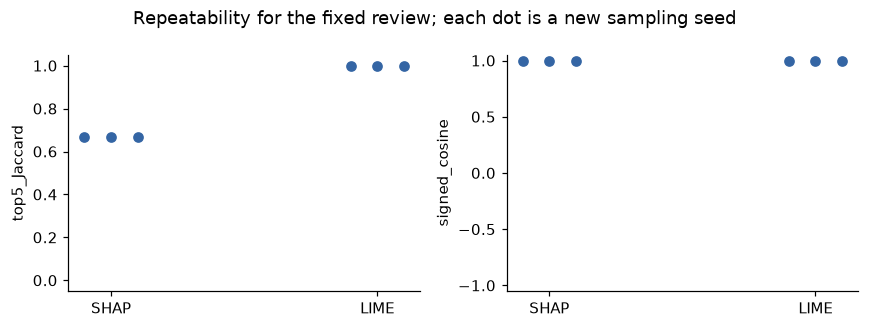

In [8]:
stability_rows = []
for seed in [101, 202, 303]:
    repeat = explain_masks(mask_score, words, seed)
    for method in ['SHAP','LIME']:
        overlap, cosine = similarity(repeat[method], shared[method], k=min(5,d))
        stability_rows.append({'method':method, 'seed':seed, 'top5_Jaccard':overlap,
                               'signed_cosine':cosine, 'case_gap':repeat['lime_case_gap'] if method=='LIME' else abs(repeat['shap_reference']+repeat[method].sum()-query_score)})
stability = pd.DataFrame(stability_rows)
display(stability.round(3))
fig, axes = plt.subplots(1, 2, figsize=(8,3))
for ax, metric in zip(axes, ['top5_Jaccard','signed_cosine']):
    for index, method in enumerate(['SHAP','LIME']):
        values = stability.loc[stability.method==method, metric]
        ax.scatter(index+np.linspace(-.1,.1,len(values)), values, color='#3465a4')
    ax.set(xticks=[0,1], xticklabels=['SHAP','LIME'], ylabel=metric, ylim=(-.05,1.05) if metric=='top5_Jaccard' else (-1.05,1.05))
fig.suptitle('Repeatability for the fixed review; each dot is a new sampling seed')
plt.tight_layout()
plt.show()

## Challenge rankings with a common deletion test and random controls

Rank word types by absolute scores and remove them progressively using the exact same masker. Plot **original minus masked target log odds**. Removing negative evidence can increase the score, so a curve need not be monotone or positive. The 30 random-order curves provide a reference with shuffle variability; this is not uncertainty across independent texts.

All methods start at the original text and end at the same empty text. Kernel SHAP and occlusion directly use related deletion operations, so this test favors a particular explanatory question. Unnatural deletions, TF-IDF normalization, word grouping and empty-text baseline influence results. No “best method” is inferred from one curve. Constant score vectors are explicitly excluded from ranking.

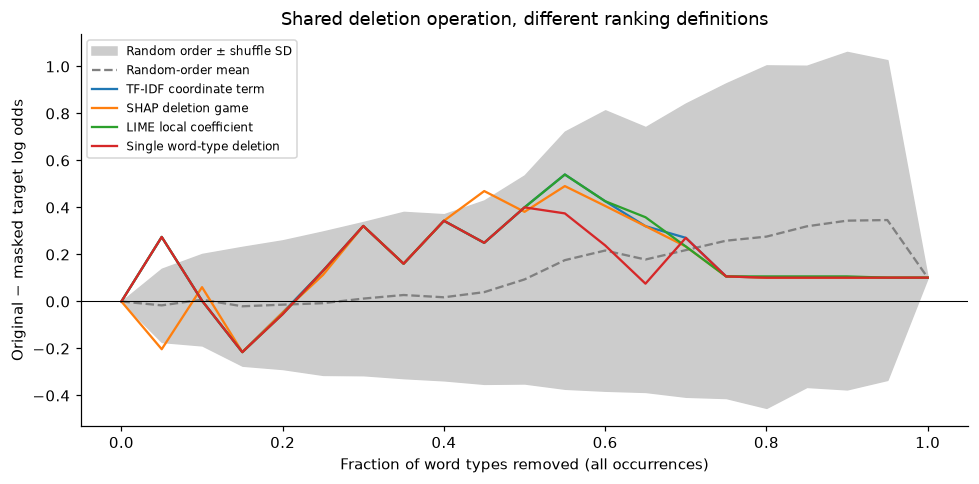

Constant vectors without a meaningful ranking: none


In [9]:
constant = [name for name, values in scores.items() if np.ptp(np.abs(values)) < 1e-12]
curves = {name:deletion_curve(mask_score, np.argsort(-np.abs(values), kind='stable'))
          for name,values in scores.items() if name not in constant}
rng = np.random.default_rng(987)
random_curves = np.array([deletion_curve(mask_score, rng.permutation(d)) for _ in range(30)])
x = np.arange(d+1)/d
fig, ax = plt.subplots(figsize=(9,4.5))
mean, sd = random_curves.mean(axis=0), random_curves.std(axis=0)
ax.fill_between(x,mean-sd,mean+sd,color='0.8',label='Random order ± shuffle SD')
ax.plot(x,mean,'--',color='gray',label='Random-order mean')
for name, curve in curves.items():
    ax.plot(x,curve,label=name)
for curve in [*curves.values(),*random_curves]:
    np.testing.assert_allclose(curve[0],0,atol=1e-12)
    np.testing.assert_allclose(curve[-1],query_score-empty_score,atol=1e-12)
ax.axhline(0,color='black',lw=.7)
ax.set(xlabel='Fraction of word types removed (all occurrences)',ylabel='Original − masked target log odds',title='Shared deletion operation, different ranking definitions')
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(OUTPUT / 'shared_text_deletion.png',bbox_inches='tight')
plt.show()
print('Constant vectors without a meaningful ranking:', constant or 'none')

## Anchors: sufficient conditions under this same artificial deletion model

Use Anchor's **binary tabular interface** on the word-presence masks; the callback reconstructs exactly the same text and queries the same classifier. This avoids a different tokenizer or language-model replacement distribution. A rule says that retaining these word types usually preserves the shared case's predicted class. It does not assign additive contributions or require all its words to have positive SHAP values.

Search with requested precision 0.95 and at most four conditions, using 2,048 independent Bernoulli masks as the sampling pool. The bounded search may return a rule below the requested precision. Report the search estimates and independently evaluate the selected rule on **new** uniform deletion masks. The binomial interval describes sampling uncertainty under that artificial distribution, not a guarantee about natural-language sentences. Coverage is the chance that a fresh mask contains the rule.

In [10]:
np.random.seed(SEED)
anchor_masks = np.random.default_rng(700).integers(0,2,size=(2048,d))
anchor_explainer = anchor_tabular.AnchorTabularExplainer(
    class_names=CLASS_NAMES, feature_names=words, train_data=anchor_masks,
    categorical_names={j:['absent','present'] for j in range(d)},
)
anchor_result = anchor_explainer.explain_instance(all_present[0], mask_class,
                                               threshold=.95, delta=.1, tau=.1, batch_size=100,
                                               max_anchor_size=min(4,d), coverage_samples=2000)
anchor_features = list(map(int,anchor_result.features()))
assert all(all_present[0,index]==1 for index in anchor_features)
probe_rng = np.random.default_rng(701)
coverage_probe = probe_rng.integers(0,2,size=(4000,d))
coverage = float(np.all(coverage_probe[:,anchor_features]==1,axis=1).mean())
conditional_probe = probe_rng.integers(0,2,size=(2000,d))
conditional_probe[:,anchor_features] = 1
matches = mask_class(conditional_probe)==TARGET
successes = int(matches.sum())
interval = binomtest(successes,len(matches)).proportion_ci(confidence_level=.95)
anchor_summary = pd.Series({'target_class':CLASS_NAMES[TARGET],
                             'rule':' AND '.join(f'{words[index]!r} present' for index in anchor_features) or '(empty rule)',
                             'conditions':len(anchor_features), 'requested_precision':.95,
                             'search_precision':float(anchor_result.precision()),
                             'search_coverage':float(anchor_result.coverage()),
                             'fresh_mask_precision':float(matches.mean()),
                             'fresh_precision_interval_low':float(interval.low),
                             'fresh_precision_interval_high':float(interval.high),
                             'fresh_mask_coverage':coverage,
                             'fresh_precision_meets_requested':bool(matches.mean()>=.95)})
display(anchor_summary)
# These are invented deletion examples. Do not present them as real corpus sentences.
probe_examples = masker.texts(conditional_probe[:5])
display(pd.DataFrame({'masked_example':probe_examples,
                      'predicted_label':[CLASS_NAMES[int(value)] for value in mask_class(conditional_probe[:5])]}))

target_class                                               negative
rule                               'all' present AND 'been' present
conditions                                                        2
requested_precision                                            0.95
search_precision                                           0.963303
search_coverage                                              0.2545
fresh_mask_precision                                         0.9615
fresh_precision_interval_low                               0.952114
fresh_precision_interval_high                              0.969499
fresh_mask_coverage                                          0.2465
fresh_precision_meets_requested                                True
dtype: object

,masked_example,predicted_label
0,all the all the of a tale has been pardon the ...,negative
1,all all good vampire been pun sucked,negative
2,all sensuality all been sucked out and replace...,negative
3,all the sensuality all the a good vampire tale...,negative
4,all the all the eroticism of a good vampire be...,negative


## Save the protocol and interpret its limits

The snapshot records corpus hashes, split/cohort identities, the exact target and tokenization, sampling budgets, package versions and diagnostics. It stores explanations, not a serialized deployed model. All computation uses the fitted pipeline; no explainer refits vocabulary or IDF on perturbations.

This comparison cannot establish semantic understanding, causal effects of language, reliability on another review population, or the usefulness of explanations to readers. The model ignores order, so it cannot distinguish every negation or phrase that people can. Inspect common function words among the leading contributions and Anchor conditions: a statistically sufficient rule can reflect corpus correlations without offering a convincing semantic rationale. Add a contextual model only with a new explicit token/masking protocol; changing the model changes the object being explained.

In [11]:
attribution_table.to_csv(OUTPUT/'attributions.csv')
cohort_diagnostics.to_csv(OUTPUT/'cohort.csv',index=False)
stability.to_csv(OUTPUT/'stability.csv',index=False)
report = {'schema_version':1, 'study':'Shared text comparison', 'seed':SEED,
          'source_sha256':{name:hashlib.sha256(Path(name).read_bytes()).hexdigest() for name in ['Shared_Text_Comparison.ipynb','text_helpers.py']},
          'corpus_sha256':{path.name:hashlib.sha256(path.read_bytes()).hexdigest() for path in sorted(corpus_directory.glob('rt-polarity.*'))},
          'train_ids':train_ids.tolist(),'test_ids':test_ids.tolist(),'cohort_ids':cohort_ids.tolist(),
          'query_id':query_id,'target_label':TARGET,'class_names':CLASS_NAMES,
          'tokenization':'Unicode word tokens, casefold, one binary feature per distinct type; remove all occurrences',
          'model':'training-fitted unigram L2 TF-IDF (min_df=2), LogisticRegression(C=1)',
          'units':'target-class log odds, except Anchor precision/coverage and dimensionless similarity metrics',
          'mask_baseline':'empty text','cohort_seed':137,'shared_SHAP_budget':512,'shared_LIME_samples':2000,
          'cohort_SHAP_budget':256,'cohort_LIME_samples':1000,'repeat_seeds':[101,202,303],
          'fresh_LIME_masks':512,'anchor_max_conditions':min(4,d),'anchor_requested_precision':.95,
          'anchor_search_pool':2048,'anchor_pool_seed':700,'anchor_probe_seed':701,
          'anchor_fresh_precision_masks':2000,'anchor_fresh_coverage_masks':4000,
          'anchor_delta':.1,'anchor_tau':.1,'deletion_orders':30,'deletion_seed':987,
          'anchor_summary':json.loads(anchor_summary.to_json()),
          'quality':json.loads(quality.to_json()),'local_diagnostics':json.loads(diagnostics.to_json()),
          'cohort':json.loads(cohort_diagnostics.to_json(orient='records')),
          'stability':json.loads(stability.to_json(orient='records')),
          'environment':{'python':platform.python_version(),'platform':platform.platform(),
                         'packages':{name:importlib.metadata.version(name) for name in ['numpy','scikit-learn','shap','lime','anchor-exp']}},
          'limits':['Group-split duplicates, but no author/movie identifiers.',
                    'Uniform word deletion can produce unnatural sentences.',
                    'TF-IDF coordinate contributions are not raw-word Shapley values.',
                    'One fixed case and a small prespecified cohort; no universal method ranking.']}
(OUTPUT/'results.json').write_text(json.dumps(report,indent=2,allow_nan=False)+'\n')
print('Saved diagnostics and figures to',OUTPUT)

Saved diagnostics and figures to /Users/navid/Documents/Codex/2026-10-28/makew/work/Introduction-to-XAI/validation/text-comparison


## Sources and exercises

- Data: [Pang and Lee's sentence polarity dataset v1.0](https://www.cs.cornell.edu/people/pabo/movie-review-data/), 5,331 snippets per class. This notebook reuses the existing bundled files and does not change their licensing.
- [Scikit-learn TF-IDF documentation](https://scikit-learn.org/stable/modules/feature_extraction.html#tfidf-term-weighting) explains normalization and learned inverse document frequencies.
- SHAP: [Lundberg and Lee (2017)](https://arxiv.org/abs/1705.07874) and [KernelExplainer](https://shap.readthedocs.io/en/latest/generated/shap.KernelExplainer.html).
- LIME: [Ribeiro, Singh and Guestrin (2016)](https://arxiv.org/abs/1602.04938) and [LimeTabularExplainer](https://lime-ml.readthedocs.io/en/latest/lime.html#module-lime.lime_tabular).
- Anchors: [Ribeiro, Singh and Guestrin (2018)](https://homes.cs.washington.edu/~marcotcr/aaai18.pdf).

**Try next:** compare `norm=None` with L2 normalization after separately refitting the model; study repeated tokens and unknown vocabulary; vary LIME's neighborhood and SHAP's budget; evaluate an Anchor on a different deletion distribution. These are changes of assumptions or models, so record them rather than mixing their outputs into one ranking.